In [ ]:
library(dplyr)
library(data.table)
library(Matrix)
library(Seurat)
library(ggplot2)
library(SeuratObject) 
library(SeuratDisk)
library(future)
options(future.globals.maxSize = 500 * 1024 ^ 3)
options(warn = 0)
library(pheatmap)
library(tidyr)
library(grid)
library(VennDiagram)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


Attaching SeuratObject

Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat



In [ ]:
obj <- readRDS('/data/users/ouyangzhen/ouyangzhen_b798d9c95579444f8c51e0f5ce81ed6b/online/stereocell/mouse/P1/P1_去双胞.rds')

In [ ]:
DefaultAssay(obj) <- 'RNA'
Epi <- obj

In [ ]:
obj
head(obj,3)

An object of class Seurat 
67701 features across 10228 samples within 2 assays 
Active assay: RNA (64701 features, 0 variable features)
 1 other assay present: integrated
 2 dimensional reductions calculated: pca, umap

,orig.ident,nCount_RNA,nFeature_RNA,RNA_snn_res.0.8,seurat_clusters,percent.mt,sample,source,integrated_snn_res.0.5,integrated_snn_res.0.3,celltype,scDblFinder.class,scDblFinder.score
,<chr>,<dbl>,<int>,<chr>,<fct>,<dbl>,<chr>,<chr>,<fct>,<fct>,<fct>,<fct>,<dbl>
2736_1,SeuratProject,2188.452,859,3,1,0.5410196,SN,Single-Nuclear,1,0,1.Immature SGN,singlet,0.0037894947
1337_1,SeuratProject,3474.147,1540,1,0,0.8443963,SN,Single-Nuclear,0,0,0.Osteoblast,singlet,0.0065208622
13817_1,SeuratProject,1202.139,507,3,2,7.1421026,SN,Single-Nuclear,2,1,1.Immature SGN,singlet,0.0003486501


In [ ]:
colnames(obj@meta.data)

[1] "orig.ident"             "nCount_RNA"             "nFeature_RNA"          
 [4] "RNA_snn_res.0.8"        "seurat_clusters"        "percent.mt"            
 [7] "sample"                 "source"                 "integrated_snn_res.0.5"
[10] "integrated_snn_res.0.3" "celltype"               "scDblFinder.class"     
[13] "scDblFinder.score"

In [ ]:
table(obj$celltype)


                       0.Osteoblast                      1.Immature SGN 
                               2248                                2411 
                       2.Mesenchyme                              3.TBCs 
                               1319                                 757 
                 4.Chondrogenic MSC                       5.Fibroblasts 
                                749                                 727 
                    6.Schwann Cells                             7.SV-MC 
                                670                                 601 
                          8.OSC_ISC                        9.Macrophage 
                                173                                 169 
               10.Endothelial Cells                              11.Ery 
                                110                                  94 
                             12.SGN                13.Reissner membrane 
                                 65               

In [ ]:
table(obj$sample)


  SC   SN 
2775 7453 

In [ ]:
colorlist = c("#FFFF00", "#1CE6FF", "#FF34FF", "#FF4A46", "#008941",
              "#006FA6", "#A30059", "#FFE4E1", "#0000A6", "#63FFAC",
              "#B79762", "#004D43", "#8FB0FF", "#997D87", "#5A0007",
              "#809693", "#1B4400", "#4FC601", "#3B5DFF", "#FF2F80",
              "#BA0900", "#6B7900", "#00C2A0", "#FFAA92", "#FF90C9",
              "#B903AA", "#DDEFFF", "#7B4F4B", "#A1C299", "#0AA6D8",
              "#00A087FF", "#4DBBD5FF", "#E64B35FF", "#3C5488FF", "#F38400",
              "#A1CAF1", "#C2B280", "#848482", "#E68FAC", "#0067A5",
              "#F99379", "#604E97", "#F6A600", "#B3446C", "#DCD300",
              "#882D17", "#8DB600", "#654522", "#E25822", "#2B3D26",
              "#191970", "#000080",
              "#6495ED", "#1E90FF", "#00BFFF", "#00FFFF", "#FF1493",
              "#FF00FF", "#A020F0", "#63B8FF", "#008B8B", "#54FF9F",
              "#00FF00", "#76EE00", "#FFF68F")

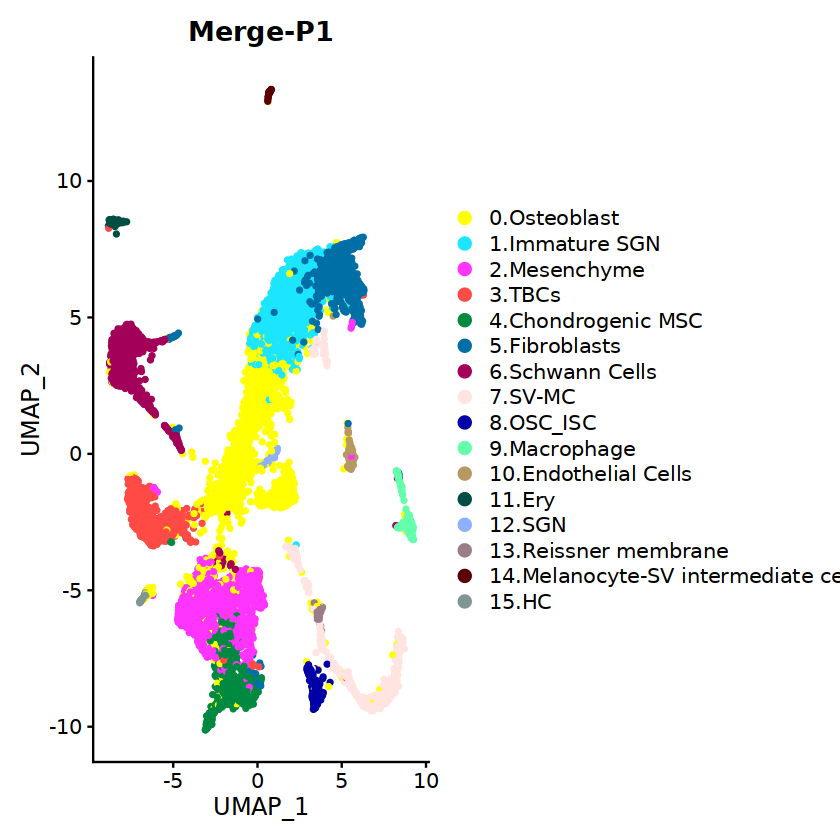

In [ ]:
p <- DimPlot(
  obj,
  label = FALSE,
  group.by = 'celltype',
  pt.size = 1,
  label.size = 8,
  cols = colorlist, 
  reduction = "umap"
) + 
  ggtitle("Merge-P1")
p
ggsave(
  "Merge-P1_UMAP.pdf",
  p,
  width = 10,
  height = 8
)

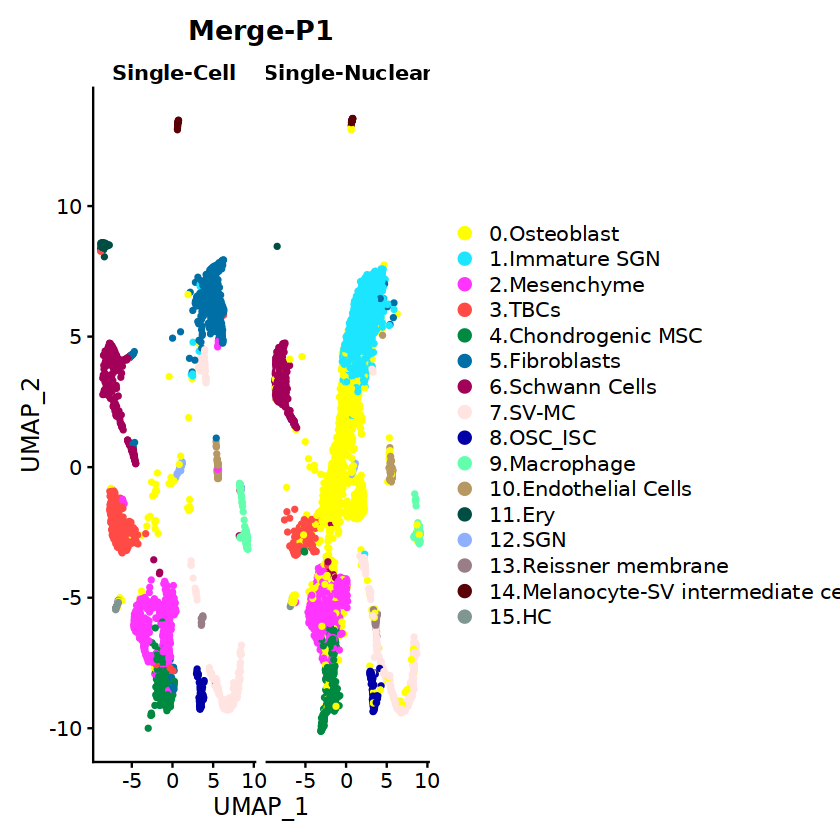

In [ ]:
p <- DimPlot(
  obj,
  label = FALSE,
  group.by = 'celltype',
  split.by = 'source', 
  pt.size = 1,
  label.size = 8,
  cols = colorlist, 
  reduction = "umap"
) + 
  ggtitle("Merge-P1")
p
ggsave(
  "Merge-P1-split_UMAP.pdf",
  p,
  width = 16,
  height = 8
)

In [ ]:
markers <- c(
"Smpd3","Phex","Pth1r","Acan",
"Col1a1","Col3a1","Dcn","Col1a2",
'Sned1', 'Enpp2', "Cdh6","Creb5",
"Col11a2","Col9a3","Col2a1", "Coch",
 "Dcn","Apod","Ctsk","H19",
"Sox10","Mpz","Plp1","Mbp",
"Kcnq1", "Esrrb", 
"Slc26a4","Lum","Epyc", "Otogl",
"Mrc1", "C1qa","C1qb",
"Pecam1","Kdr","Flt1",
"Hbb-bs","Hba-a1","Alas2",
"Neurod1","Pou4f1","Nefm","Calb2",
"Slc26a7","Dkk2","Mitf",
"Tyr","Dct","Kcnj13",
"Pou4f3","Atoh1","Otof","Slc26a5"
)

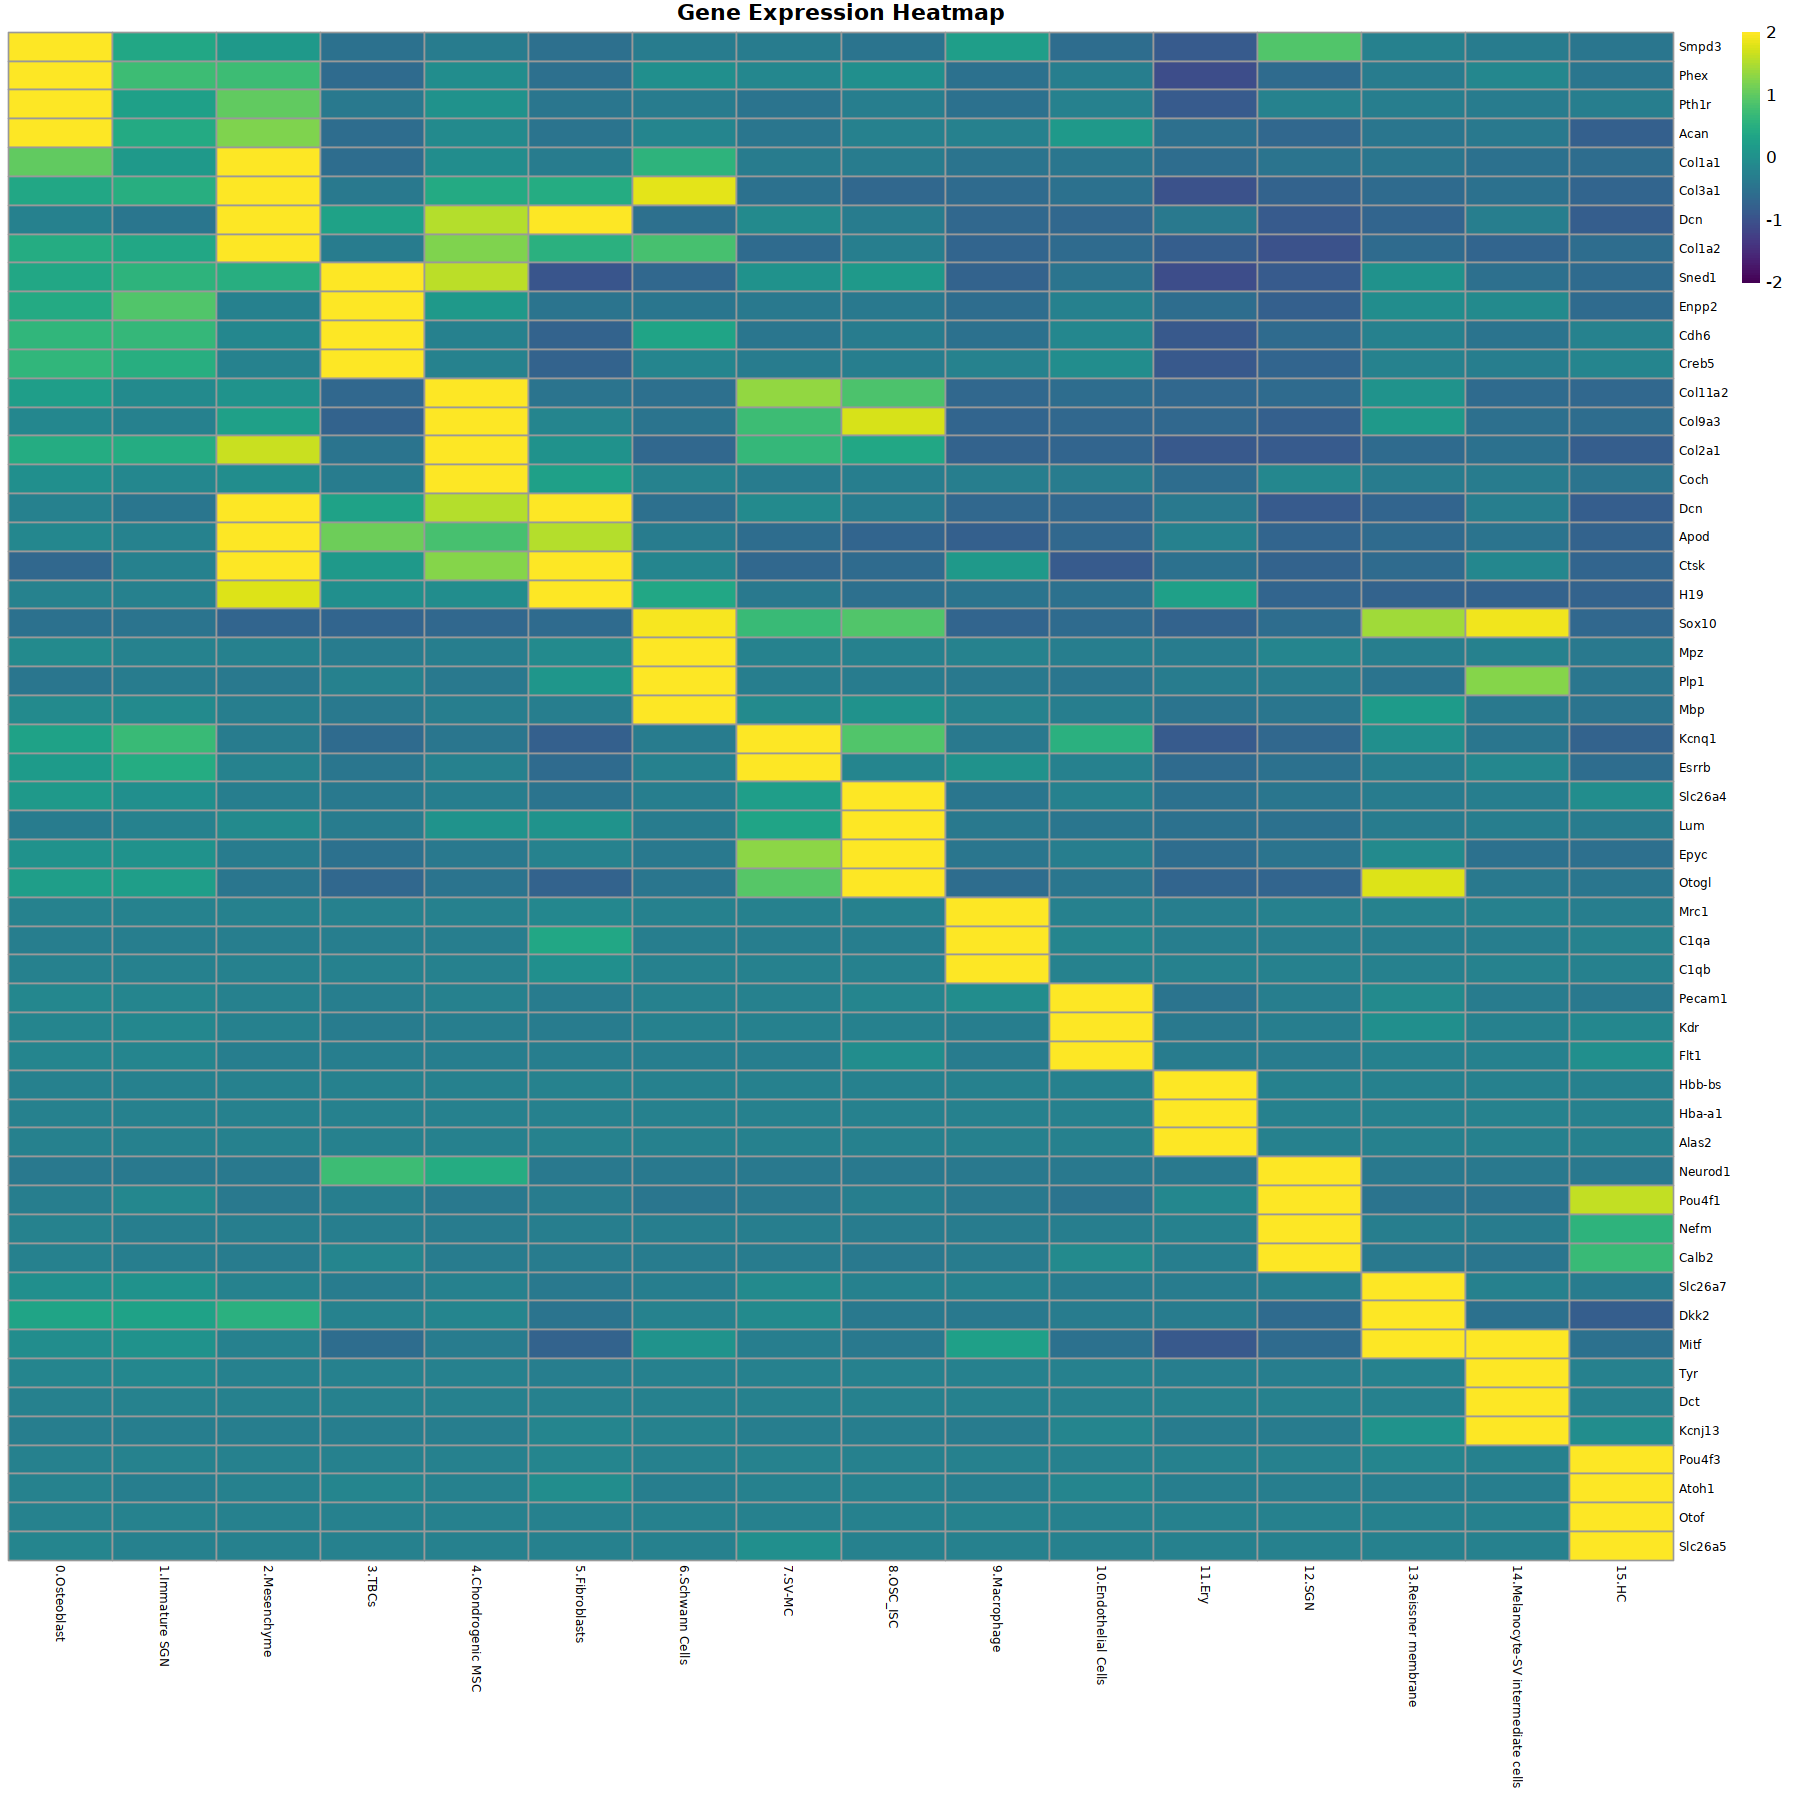

In [ ]:
id <- 'Merge-P1-注释'
expression_matrix <- GetAssayData(Epi, assay = "RNA", slot = "data")

markers <- markers[markers %in% rownames(Epi[["RNA"]])]
# 提取对应基因的表达量
cluster_expression <- expression_matrix[markers, ]

# 根据 RCTD_multi_celltype 分组并计算平均表达量
avg_expression <- AverageExpression(
  Epi, 
  assays = "RNA", 
  group.by = "celltype"
)$RNA
# 只提取 marker 基因的数据
avg_expression <- avg_expression[markers, ]
options(repr.plot.width=15,repr.plot.height=15)
# 绘制热图
mat <- t(scale(t(avg_expression)))
mat[mat >  2] <-  2
mat[mat < -2] <- -2
p <- pheatmap(
  mat,
  main = "Gene Expression Heatmap",
  color = viridisLite::viridis(100),
  breaks = seq(-2, 2, length.out = 101),
  fontsize_row = 7,
  fontsize_col = 7,
  cluster_col = FALSE,
  cluster_row = FALSE
)

ggsave(file = paste0(id, "_pheatmap.pdf"), plot = p, width = 15, height = 30)


Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


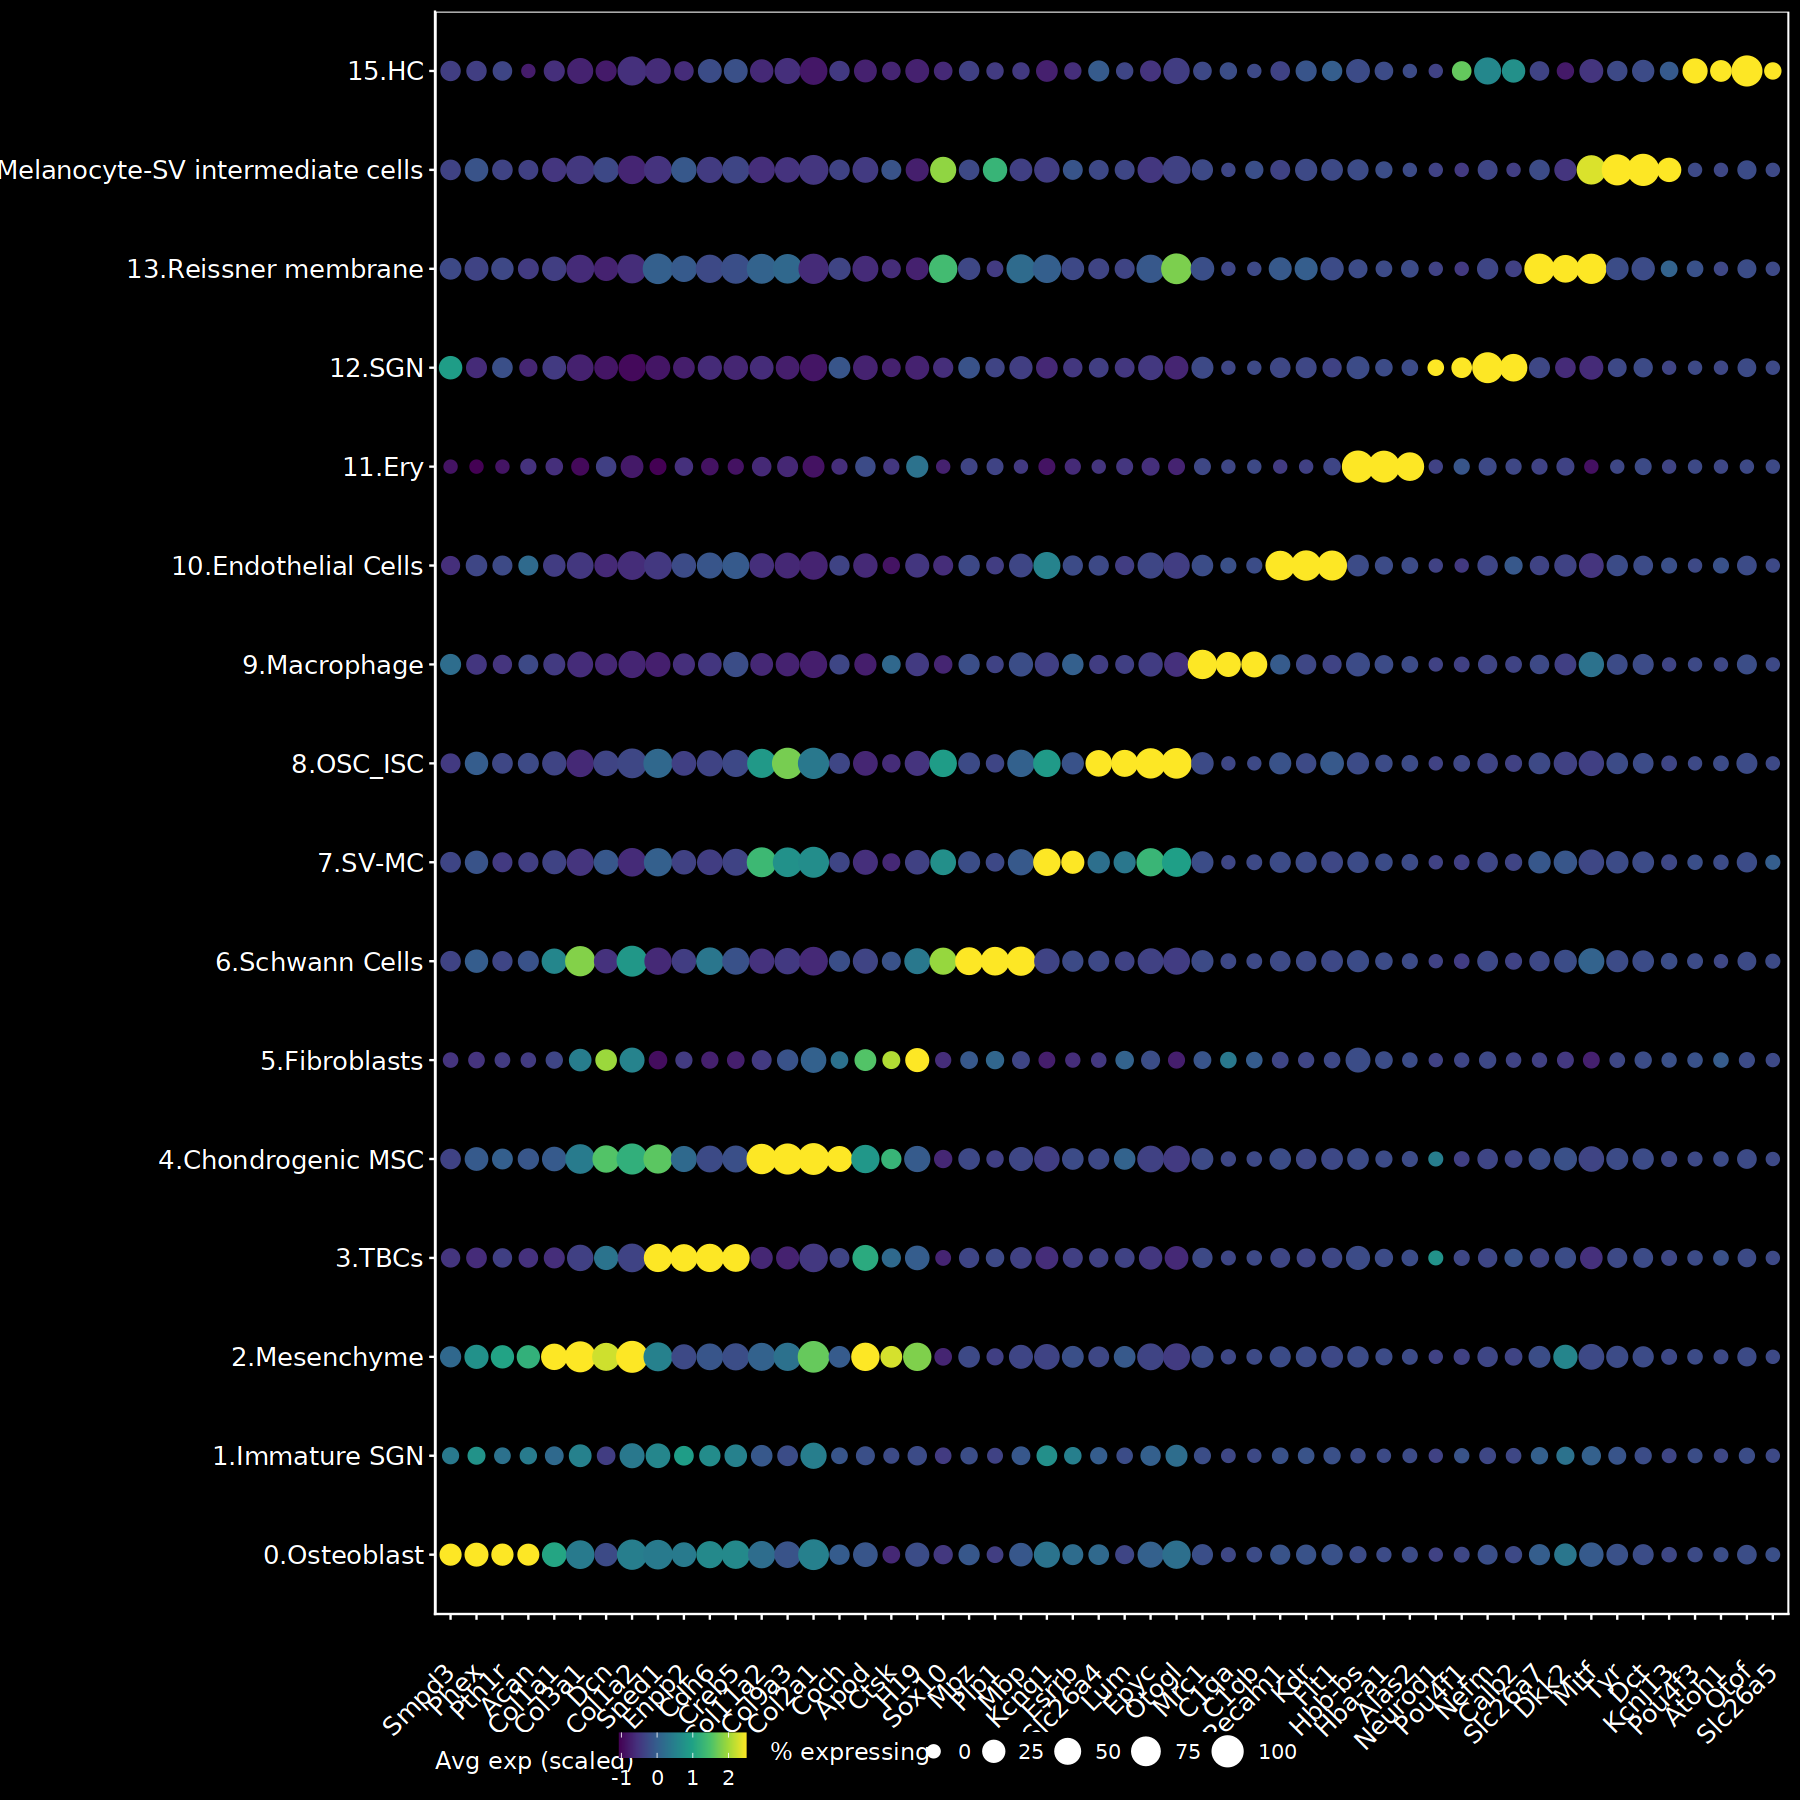

In [ ]:
p <- DotPlot(
  object = Epi,
  features = unique(markers),   # 基因顺序 = markers 首次出现顺序
  dot.scale = 5,
  scale.min = 0,
  scale.max = 100,
  group.by = 'celltype'  # 使用celltype列
) +
  scale_color_gradientn(
    colours = colorRampPalette(c("#440154", "#46327E", "#365C8D", "#277F8E", 
                                 "#1FA187", "#4AC16D", "#A0DA39", "#FDE725"))(100)
  ) +
  labs(x = NULL, y = NULL) +
  guides(
    colour = guide_colourbar(order = 1, title = "Avg exp (scaled)"),
    size = guide_legend(order = 2, title = "% expressing",
                        override.aes = list(colour = "white", fill = "white", alpha = 1))
  ) +
  scale_size_continuous(limits = c(0, 100), breaks = c(0, 25, 50, 75, 100), range = c(3, 8)) +
  theme(
    panel.background = element_rect(fill = "black", colour = NA),
    plot.background = element_rect(fill = "black", colour = NA),
    panel.grid = element_blank(),
    axis.text.x = element_text(angle = 45, hjust = 1, vjust = 0.5, colour = "white", size = 15),
    axis.text.y = element_text(colour = "white", size = 15),
    axis.ticks = element_line(colour = "white"),
    axis.line = element_line(colour = "white"),
    panel.border = element_rect(colour = "white", fill = NA),
    legend.position = "bottom",
    legend.direction = "horizontal",
    legend.background = element_rect(fill = "black", colour = NA),
    legend.title = element_text(colour = "white"),
    legend.text = element_text(colour = "white")
  )

print(p)

ggsave(filename = paste0(id, '_DotPlot.pdf'), 
       plot = p, width = 18, height = 6)


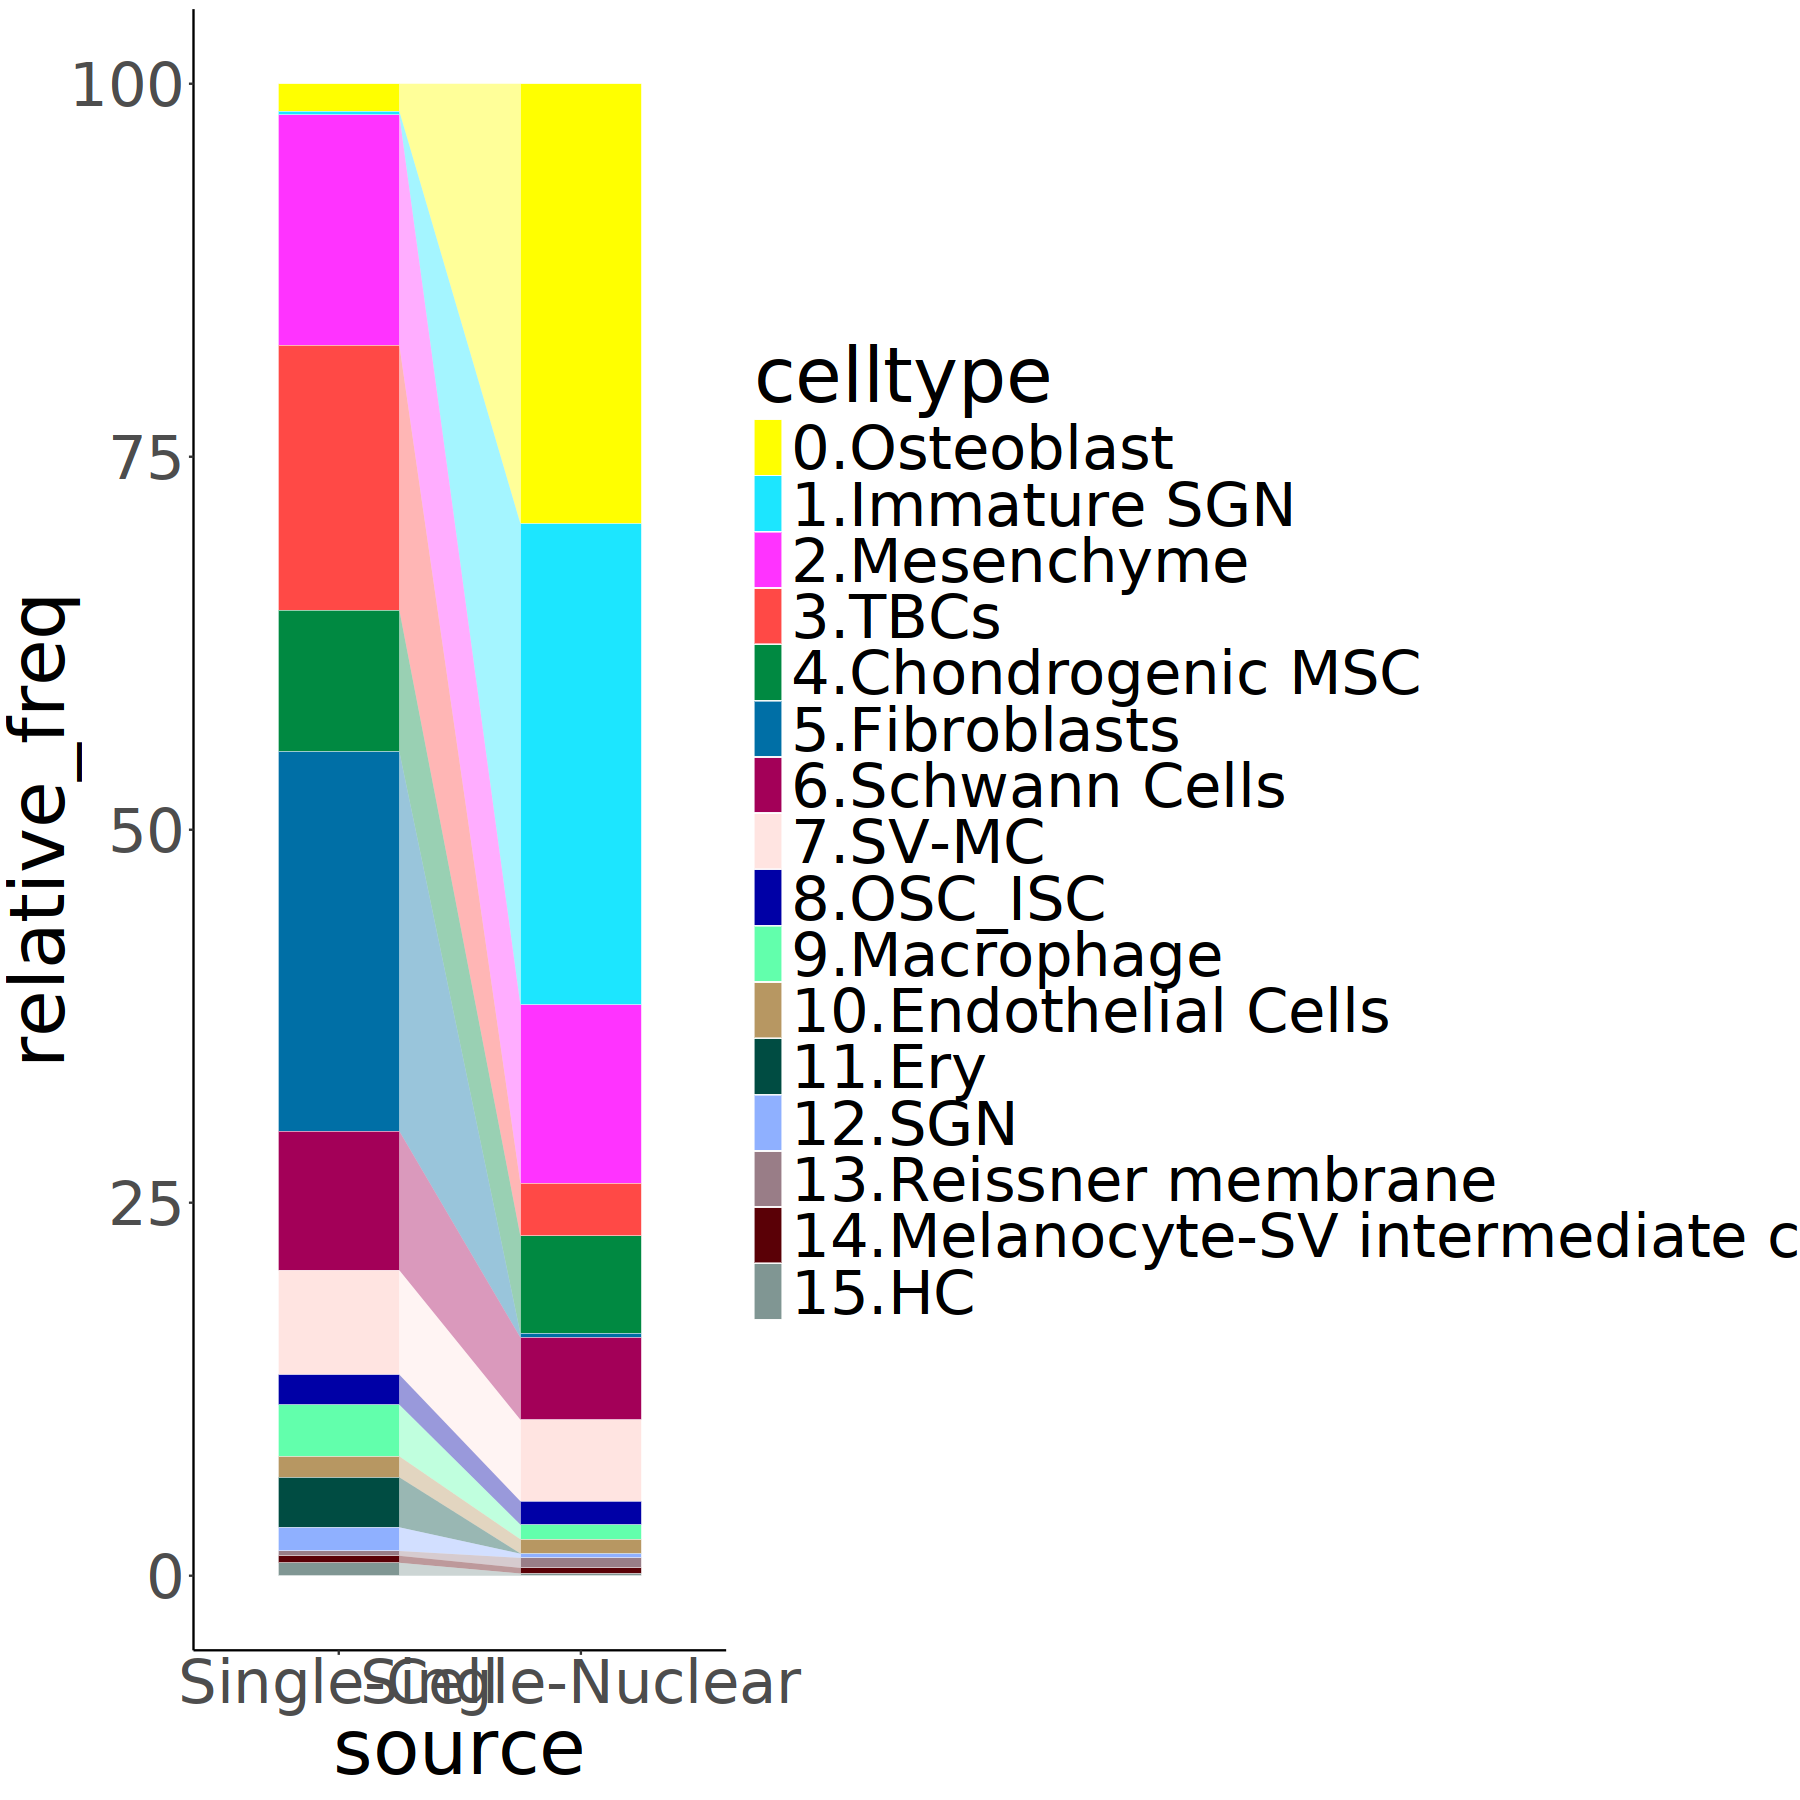

In [ ]:
library(ggplot2)
library(ggalluvial)
library(dplyr)

celltype_order <- levels(obj$celltype)
source_order <- levels(obj$source)

cell_colors <- setNames(
  colorlist[seq_along(celltype_order)],
  celltype_order
)

Ratio <- obj@meta.data %>%
  count(source, celltype, name = "n") %>%
  group_by(source) %>%
  mutate(relative_freq = n / sum(n) * 100) %>%
  ungroup()

p <- ggplot(
  Ratio,
  aes(
    x = source,
    y = relative_freq,
    fill = celltype,
    stratum = celltype,
    alluvium = celltype
  )
) +
  geom_col(
    width = 0.5,
    color = "white",
    linewidth = 0.2
  ) +
  geom_alluvium(
    width = 0.5,
    alpha = 0.4,
    curve_type = "linear"
  ) +
  scale_fill_manual(
    values = cell_colors,
    drop = FALSE
  ) +
  theme_classic() +
  theme(
    text = element_text(size = 45),
    panel.grid = element_blank(),
    panel.background = element_blank()
  )

p

ggsave(
  "P1_celltype_ratio-V1.pdf",
  p,
  width = 25,
  height = 15
)

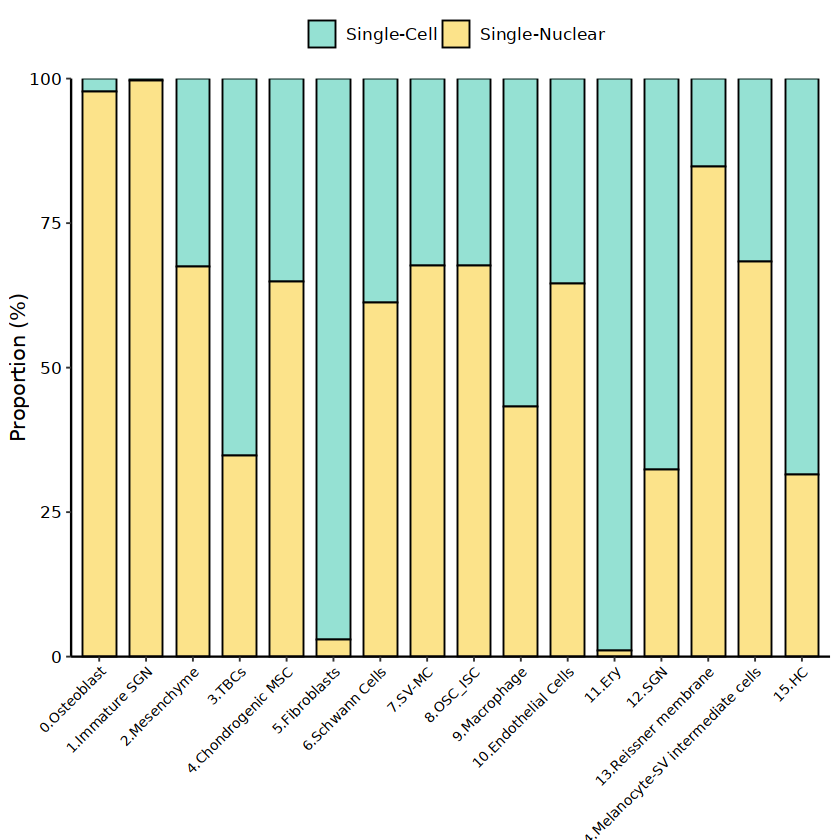

In [ ]:
library(ggplot2)
library(dplyr)

source_order <- unique(as.character(obj$source))

source_colors <- 
#  c('Single-Nuclear' = "#ADDCCA", 
#    'Single-Cell' = "#18A4E0")
  c('Single-Nuclear' = "#fce38a", 
    'Single-Cell' = "#95e1d3")
#  c('Single-Nuclear' = "#fadde0", 
#    'Single-Cell' = "#dcd1fa")

Ratio <- obj@meta.data %>%
  count(source, celltype, name = "n") %>%
  group_by(celltype) %>%
  mutate(
    relative_freq = n / sum(n) * 100
  ) %>%
  ungroup()

p <- ggplot(
  Ratio,
  aes(
    x = celltype,
    y = relative_freq,
    fill = source
  )
) +
  geom_col(
    width = 0.72,
    color = "black",
    linewidth = 0.4
  ) +
  scale_fill_manual(
    values = source_colors
  ) +
  scale_y_continuous(
    breaks = seq(0, 100, 25),
    expand = c(0, 0)
  ) +
  coord_cartesian(
    ylim = c(0, 100)
  ) +
  labs(
    x = NULL,
    y = "Proportion (%)",
    fill = NULL
  ) +
  theme_classic(base_size = 12) +
  theme(
    axis.text.x = element_text(
      angle = 45,
      hjust = 1,
      size = 8,
      color = "black"
    ),
    axis.text.y = element_text(
      size = 10,
      color = "black"
    ),
    axis.title.y = element_text(
      size = 12
    ),
    axis.line = element_line(
      linewidth = 0.5,
      color = "black"
    ),
    axis.ticks = element_line(
      linewidth = 0.4
    ),
    legend.position = "top",
    legend.text = element_text(size = 10),
    panel.grid = element_blank()
  )

p

ggsave(
  "P1_celltype_ratio.pdf",
  plot = p,
  width = 6,
  height = 5
)

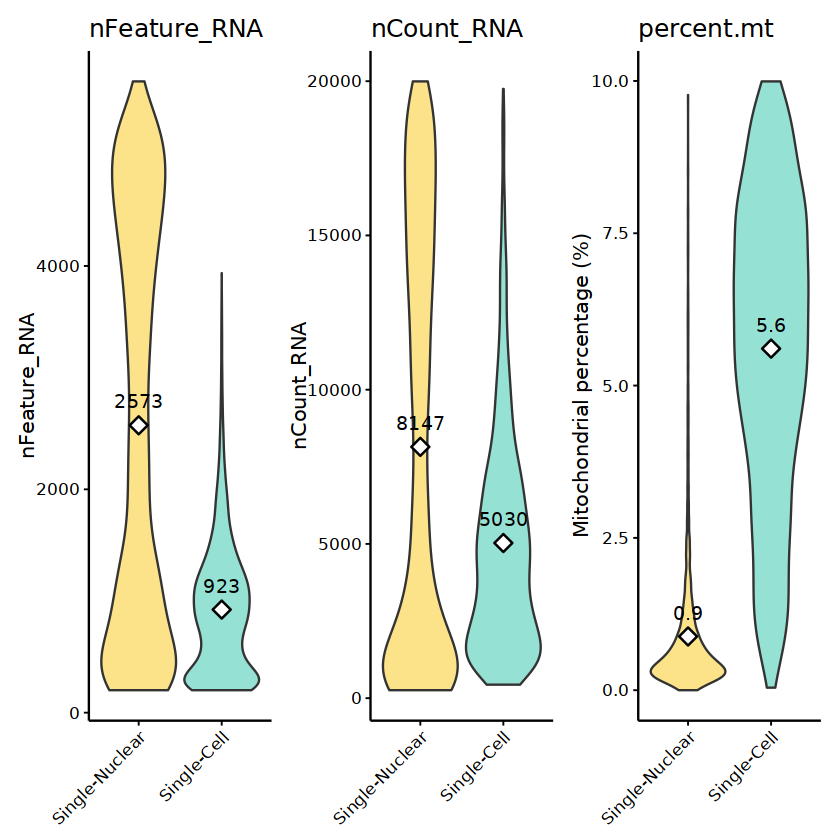

In [ ]:
library(patchwork)
source_colors <- c(
  "Single-Nuclear"="#fce38a",
  "Single-Cell"="#95e1d3"
)

obj$source <- factor(
  obj$source,
  levels=c("Single-Nuclear","Single-Cell")
)

plot_vln <- function(feature, ylab, digits=0){

  df_mean <- obj@meta.data %>%
    group_by(source) %>%
    summarise(
      value=mean(.data[[feature]],na.rm=TRUE),
      .groups="drop"
    )

  VlnPlot(
    obj,
    features=feature,
    group.by="source",
    cols=source_colors,
    pt.size=0
  ) +
    geom_point(
      data=df_mean,
      aes(x=source,y=value),
      inherit.aes=FALSE,
      shape=23,
      size=3.5,
      fill="white",
      color="black",
      stroke=0.8
    ) +
    geom_text(
      data=df_mean,
      aes(
        x=source,
        y=value,
        label=round(value,digits)
      ),
      inherit.aes=FALSE,
      vjust=-1.2,
      size=4,
      color="black"
    ) +
    labs(
      x=NULL,
      y=ylab
    ) +
    theme_classic(base_size=12) +
    theme(
      legend.position="none",
      axis.text.x=element_text(
        angle=45,
        hjust=1,
        size=10,
        color="black"
      ),
      axis.text.y=element_text(
        size=10,
        color="black"
      ),
      axis.title.y=element_text(
        size=12,
        color="black"
      ),
      axis.line=element_line(
        linewidth=0.5,
        color="black"
      ),
      axis.ticks=element_line(
        linewidth=0.4,
        color="black"
      ),
      panel.grid=element_blank()
    )
}

p1 <- plot_vln(
  "nFeature_RNA",
  "nFeature_RNA",
  digits=0
)

p2 <- plot_vln(
  "nCount_RNA",
  "nCount_RNA",
  digits=0
)

p3 <- plot_vln(
  "percent.mt",
  "Mitochondrial percentage (%)",
  digits=1
)

p <- p1 + p2 + p3 +
  plot_layout(ncol=3)

print(p)

ggsave(
  "P1_QC_Violin.pdf",
  plot=p,
  width=14,
  height=4
)

In [ ]:
table(obj$celltype, obj$source)

                                     
                                      Single-Cell Single-Nuclear
  0.Osteoblast                                 51           2197
  1.Immature SGN                                7           2404
  2.Mesenchyme                                428            891
  3.TBCs                                      493            264
  4.Chondrogenic MSC                          263            486
  5.Fibroblasts                               706             21
  6.Schwann Cells                             259            411
  7.SV-MC                                     194            407
  8.OSC_ISC                                    56            117
  9.Macrophage                                 96             73
  10.Endothelial Cells                         39             71
  11.Ery                                       93              1
  12.SGN                                       44             21
  13.Reissner membrane                          9   

In [ ]:
source_colors <- 
  c("#D94B4B", "#F39C34")
p <- VlnPlot(
  obj,
  features = c("nFeature_RNA"),
  group.by = "celltype",
  split.by = 'source', 
  pt.size = 0,
  cols = source_colors, 
  ncol = 2
)
ggsave('Merge-P1-QC-celltype.pdf', p, width = 12, height = 5)

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


In [ ]:
avg_expr <- AverageExpression(
  obj,
  assays = "RNA",
  slot = "data",
  group.by = "source",
  verbose = FALSE
)$RNA

df <- data.frame(
  x = log1p(avg_expr[, "Single-Cell"]),
  y = log1p(avg_expr[, "Single-Nuclear"])
)

fit <- lm(y ~ x, data = df)
r2 <- summary(fit)$r.squared
coef_fit <- coef(fit)

eq_lab <- paste0(
  "R² = ", sprintf("%.4f", r2), "\n",
  "y = ", sprintf("%.4f", coef_fit[2]), "x ",
  ifelse(coef_fit[1] >= 0, "+ ", "- "),
  sprintf("%.4f", abs(coef_fit[1]))
)

p <- ggplot(df, aes(x = x, y = y)) +
  geom_point(size = 0.5, alpha = 0.8, color = "#2E86DE") +
  geom_smooth(method = "lm", se = FALSE, color = "#FF2D7A", linewidth = 1.2) +
  annotate(
    "text",
    x = min(df$x),
    y = max(df$y),
    label = eq_lab,
    hjust = 0,
    vjust = 1,
    size = 4
  ) +
  labs(
    x = "Normalized expression\n(Single-Cell)",
    y = "Normalized expression\n(Single-Nuclear)"
  ) +
  theme_classic() +
  theme(
    axis.title = element_text(size = 12),
    axis.text = element_text(size = 10)
  )

pdf("Merge-P1_correlation_plot.pdf", width = 4.5, height = 4.5)
print(p)
dev.off()

In [ ]:
counts <- GetAssayData(
  obj,
  assay = "RNA",
  slot = "counts"
)

meta <- obj@meta.data

celltypes <- unique(meta$celltype)

detected_list <- lapply(celltypes, function(ct) {

  cells_sc <- rownames(meta)[
    meta$celltype == ct &
    meta$source == "Single-Cell"
  ]

  cells_sn <- rownames(meta)[
    meta$celltype == ct &
    meta$source == "Single-Nuclear"
  ]

  if(length(cells_sc) == 0 | length(cells_sn) == 0) {
    return(NULL)
  }

  n_gene_sc <- sum(
    Matrix::rowSums(counts[, cells_sc, drop = FALSE] > 0) > 0
  )

  n_gene_sn <- sum(
    Matrix::rowSums(counts[, cells_sn, drop = FALSE] > 0) > 0
  )

  data.frame(
    celltype = ct,
    Single_Cell = n_gene_sc,
    Single_Nuclear = n_gene_sn
  )
})

df_detected <- bind_rows(detected_list)

df_detected

celltype,Single_Cell,Single_Nuclear
<fct>,<int>,<int>
1.Immature SGN,1907,29492
0.Osteoblast,13017,43975
2.Mesenchyme,29319,43482
4.Chondrogenic MSC,26810,38830
3.TBCs,31108,33973
7.SV-MC,22460,37744
6.Schwann Cells,26025,37081
8.OSC_ISC,17959,28000
9.Macrophage,19094,24227


In [ ]:
library(ggrepel)
max_val <- max(
  df_detected$Single_Cell,
  df_detected$Single_Nuclear
)

p <- ggplot(
  df_detected,
  aes(
    x = Single_Cell,
    y = Single_Nuclear
  )
) +
  geom_abline(
    slope = 1,
    intercept = 0,
    linetype = "dashed",
    color = "grey50",
    linewidth = 0.7
  ) +
  geom_point(
    size = 3,
    color = "#2E86DE"
  ) +
  geom_text_repel(
    aes(label = celltype),
    size = 3
  ) +
  coord_equal(
    xlim = c(0, max_val * 1.05),
    ylim = c(0, max_val * 1.05)
  ) +
  labs(
    x = "Detected genes\n(Single-Cell)",
    y = "Detected genes\n(Single-Nuclear)"
  ) +
  theme_classic() +
  theme(
    axis.title = element_text(size = 12),
    axis.text = element_text(size = 10)
  )

ggsave(
  "Merge-P1_detected_genes_by_celltype.pdf",
  p,
  width = 5,
  height = 5
)

In [ ]:
obj <- readRDS('Merge-Cochlea-Final-V3.rds')

In [ ]:
obj
head(obj,3)

An object of class Seurat 
68980 features across 13926 samples within 2 assays 
Active assay: integrated (3000 features, 3000 variable features)
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

,orig.ident,nCount_RNA,nFeature_RNA,sample,percent.mt,RNA_snn_res.0.5,seurat_clusters,source,SN,RNA_snn_res.0.8,⋯,integrated_snn_res.0.3,celltype,celltype_0813,scDblFinder.class,scDblFinder.score,celltype_1006,keep_flag,integrated_snn_res.0.5,celltype_1013,celltype_1013_Epi
,<chr>,<dbl>,<int>,<chr>,<dbl>,<chr>,<fct>,<chr>,<chr>,<chr>,⋯,<fct>,<chr>,<fct>,<fct>,<dbl>,<chr>,<lgl>,<fct>,<fct>,<fct>
AAACCCAAGTTCATGC-1_2,3M_Cochlea_snRNA,954,694,3M_sn_Cochlea,0.8385744,6,3,snRNA,NA,NA,⋯,3,10.Claudius_Inner_Outer_Sulcus_Cells,10.SCs,singlet,1.719108e-05,NA,TRUE,2,10.SCs,10.SCs
AAACGAAAGCCTAGGA-1_2,3M_Cochlea_snRNA,4939,2514,3M_sn_Cochlea,0.4656813,1,5,snRNA,NA,NA,⋯,5,6.Reissner_Membrane,6.RM,singlet,7.581586e-05,NA,TRUE,5,6.RM,6.6.RM
AAACGAAAGTATCTGC-1_2,3M_Cochlea_snRNA,3388,1513,3M_sn_Cochlea,0.3246753,0,1,snRNA,NA,NA,⋯,1,4.Endo,4.TBC,singlet,3.224101e-04,NA,TRUE,0,4.TBC,4.TBC


In [ ]:
colnames(obj@meta.data)

[1] "orig.ident"             "nCount_RNA"             "nFeature_RNA"          
 [4] "sample"                 "percent.mt"             "RNA_snn_res.0.5"       
 [7] "seurat_clusters"        "source"                 "SN"                    
[10] "RNA_snn_res.0.8"        "RNA_snn_res.0.4"        "RNA_snn_res.0.3"       
[13] "integrated_snn_res.0.3" "celltype"               "celltype_0813"         
[16] "scDblFinder.class"      "scDblFinder.score"      "celltype_1006"         
[19] "keep_flag"              "integrated_snn_res.0.5" "celltype_1013"         
[22] "celltype_1013_Epi"

In [ ]:
colorlist = c("#FFFF00", "#1CE6FF", "#FF34FF", "#FF4A46", "#008941",
              "#006FA6", "#A30059", "#FFE4E1", "#0000A6", "#63FFAC",
              "#B79762", "#004D43", "#8FB0FF", "#997D87", "#5A0007",
              "#809693", "#1B4400", "#4FC601", "#3B5DFF", "#FF2F80",
              "#BA0900", "#6B7900", "#00C2A0", "#FFAA92", "#FF90C9",
              "#B903AA", "#DDEFFF", "#7B4F4B", "#A1C299", "#0AA6D8",
              "#00A087FF", "#4DBBD5FF", "#E64B35FF", "#3C5488FF", "#F38400",
              "#A1CAF1", "#C2B280", "#848482", "#E68FAC", "#0067A5",
              "#F99379", "#604E97", "#F6A600", "#B3446C", "#DCD300",
              "#882D17", "#8DB600", "#654522", "#E25822", "#2B3D26",
              "#191970", "#000080",
              "#6495ED", "#1E90FF", "#00BFFF", "#00FFFF", "#FF1493",
              "#FF00FF", "#A020F0", "#63B8FF", "#008B8B", "#54FF9F",
              "#00FF00", "#76EE00", "#FFF68F")

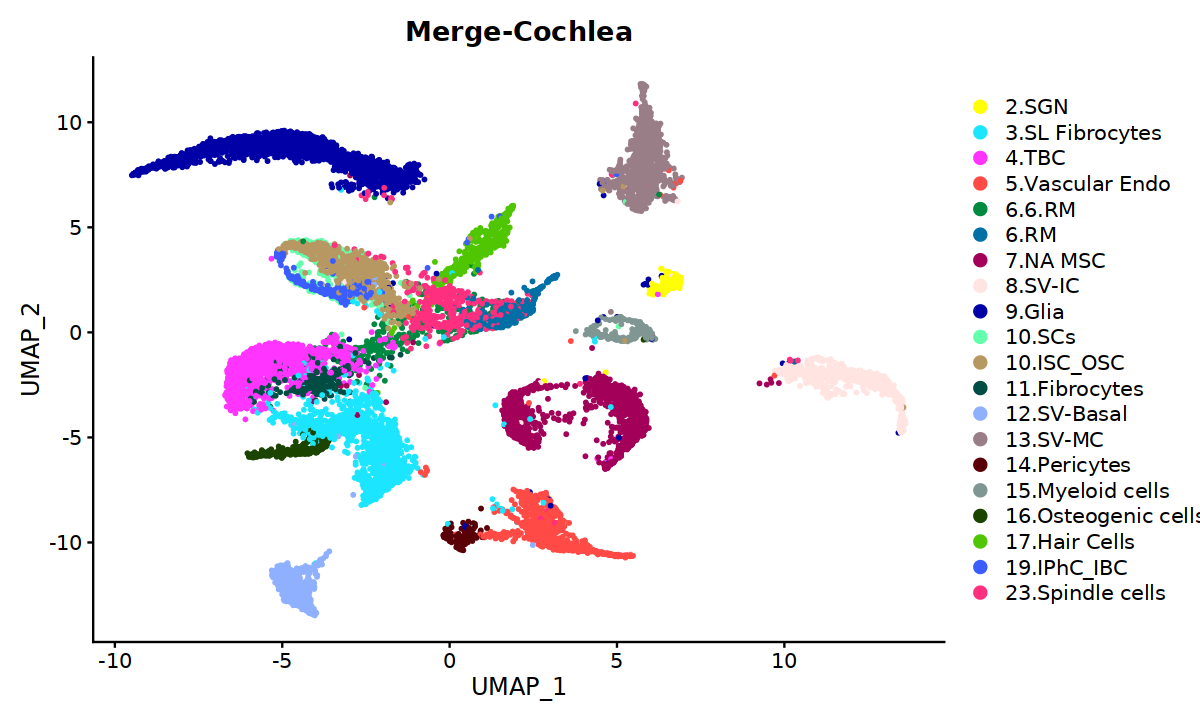

In [ ]:
p <- DimPlot(
  obj,
  label = FALSE,
  group.by = 'celltype_1013',
  pt.size = 0.6,
  label.size = 3.5,
  cols = colorlist, 
  reduction = "umap"
) + 
  ggtitle("Merge-Cochlea")
p
ggsave(
  "Merge-Adult-Cochlea_UMAP.pdf",
  p,
  width = 11,
  height = 8
)

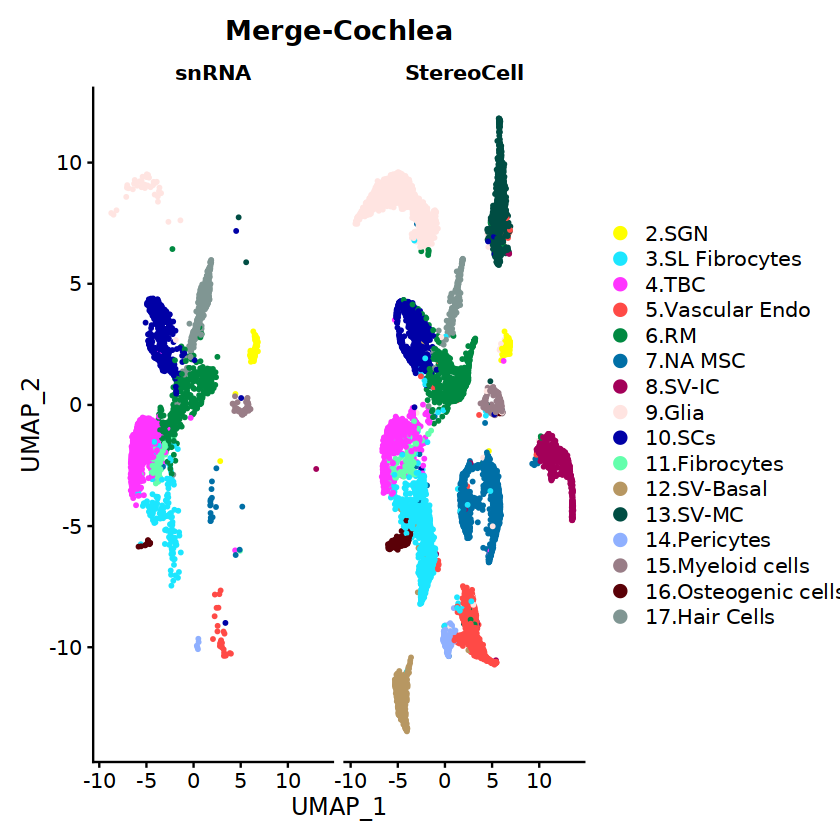

In [ ]:
p <- DimPlot(
  obj,
  label = FALSE,
  group.by = 'celltype_1013',
  pt.size = 0.6,
  label.size = 3.5,
  cols = colorlist, 
  reduction = "umap",
  split.by = 'source'
) + 
  ggtitle("Merge-Cochlea")
p
ggsave(
  "Merge-Adult-Cochlea-split_UMAP.pdf",
  p,
  width = 18,
  height = 8
)

In [ ]:
source_colors <- c("snRNA"="#95e1d3","StereoCell"="#fce38a")
mean_df <- obj@meta.data %>% group_by(source) %>% summarise(nFeature_RNA=mean(nFeature_RNA,na.rm=TRUE),nCount_RNA=mean(nCount_RNA,na.rm=TRUE),percent.mt=mean(percent.mt,na.rm=TRUE)) %>% pivot_longer(cols=c(nFeature_RNA,nCount_RNA,percent.mt),names_to="feature",values_to="mean_value")
p <- VlnPlot(obj,features=c("nFeature_RNA","nCount_RNA","percent.mt"),group.by="source",pt.size=0,cols=source_colors,combine=FALSE)
for(i in seq_along(p)){
  f <- c("nFeature_RNA","nCount_RNA","percent.mt")[i]
  p[[i]] <- p[[i]]+geom_point(data=filter(mean_df,feature==f),aes(x=source,y=mean_value),inherit.aes=FALSE,size=3,color="black")+geom_text(data=filter(mean_df,feature==f),aes(x=source,y=mean_value,label=round(mean_value,ifelse(f=="percent.mt",2,0))),inherit.aes=FALSE,vjust=-0.8,size=4,fontface="bold")+theme_classic()
}
ggsave("Merge-Cochlea-QC.pdf",p[[1]]+p[[2]]+p[[3]],width=12,height=5)

In [ ]:
source_colors <- 
  c("#95e1d3", "#fce38a")
p <- VlnPlot(
  obj,
  features = c("nFeature_RNA"),
  group.by = "celltype_1013",
  split.by = 'source', 
  pt.size = 0,
  cols = source_colors, 
  ncol = 2
)
ggsave('Merge-Cochlea-QC-celltype.pdf', p, width = 12, height = 5)

The default behaviour of split.by has changed.
Separate violin plots are now plotted side-by-side.
To restore the old behaviour of a single split violin,
set split.plot = TRUE.
      
This message will be shown once per session.

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


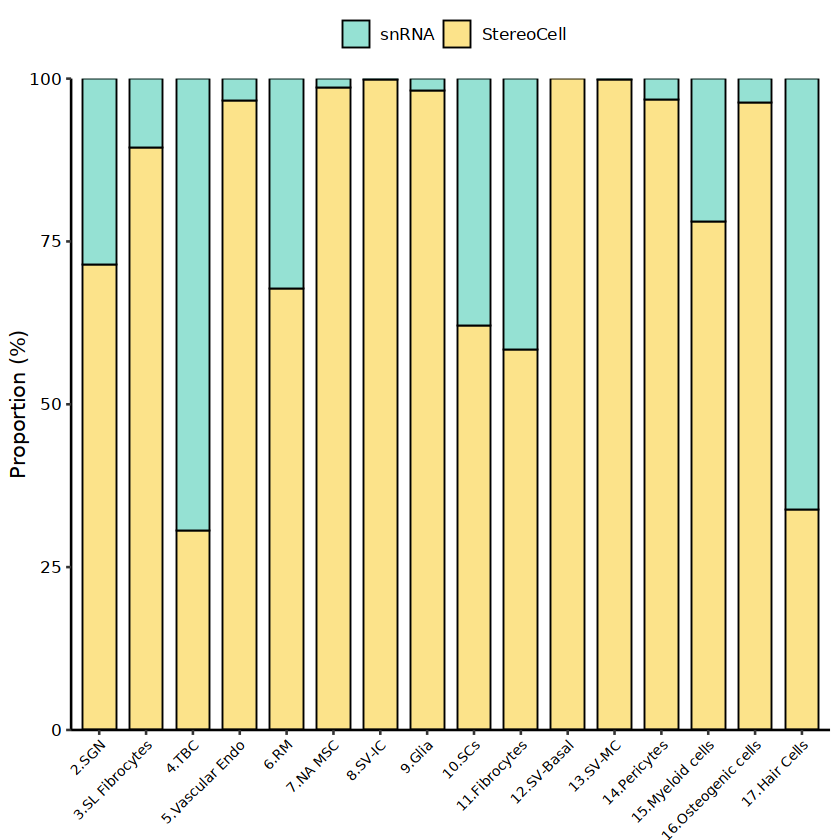

In [ ]:
source_colors <- c("snRNA"="#95e1d3","StereoCell"="#fce38a")

Ratio <- obj@meta.data %>%
  count(source,celltype_1013,name="n") %>%
  group_by(celltype_1013) %>%
  mutate(relative_freq=n/sum(n)*100) %>%
  ungroup()

p <- ggplot(Ratio,aes(celltype_1013,relative_freq,fill=source))+
  geom_col(width=.72,color="black",linewidth=.4)+
  scale_fill_manual(values=source_colors)+
  scale_y_continuous(breaks=seq(0,100,25),expand=c(0,0))+
  coord_cartesian(ylim=c(0,100))+
  labs(x=NULL,y="Proportion (%)",fill=NULL)+
  theme_classic(base_size=12)+
  theme(axis.text.x=element_text(angle=45,hjust=1,size=8,color="black"),
        axis.text.y=element_text(size=10,color="black"),
        legend.position="top",panel.grid=element_blank())

p
ggsave("Merge-Cochlea-celltype-ratio.pdf",p,width=6,height=5)

In [ ]:
library(ggalluvial)
celltype_order <- unique(as.character(obj$celltype_1013))
cell_colors <- setNames(colorlist[seq_along(celltype_order)],celltype_order)

Ratio <- obj@meta.data %>%
  count(source,celltype_1013,name="n") %>%
  group_by(source) %>%
  mutate(relative_freq=n/sum(n)*100) %>%
  ungroup()

p <- ggplot(Ratio,aes(source,relative_freq,fill=celltype_1013,
                      stratum=celltype_1013,alluvium=celltype_1013))+
  geom_col(width=.5,color="white",linewidth=.2)+
  geom_alluvium(width=.5,alpha=.4,curve_type="linear")+
  scale_fill_manual(values=cell_colors,drop=F)+
  theme_classic()+
  theme(text=element_text(size=45),panel.grid=element_blank())
ggsave("Merge-Cochlea-ratio.pdf",p,width=25,height=15)


`geom_smooth()` using formula = 'y ~ x'


pdf 
  2

`geom_smooth()` using formula = 'y ~ x'


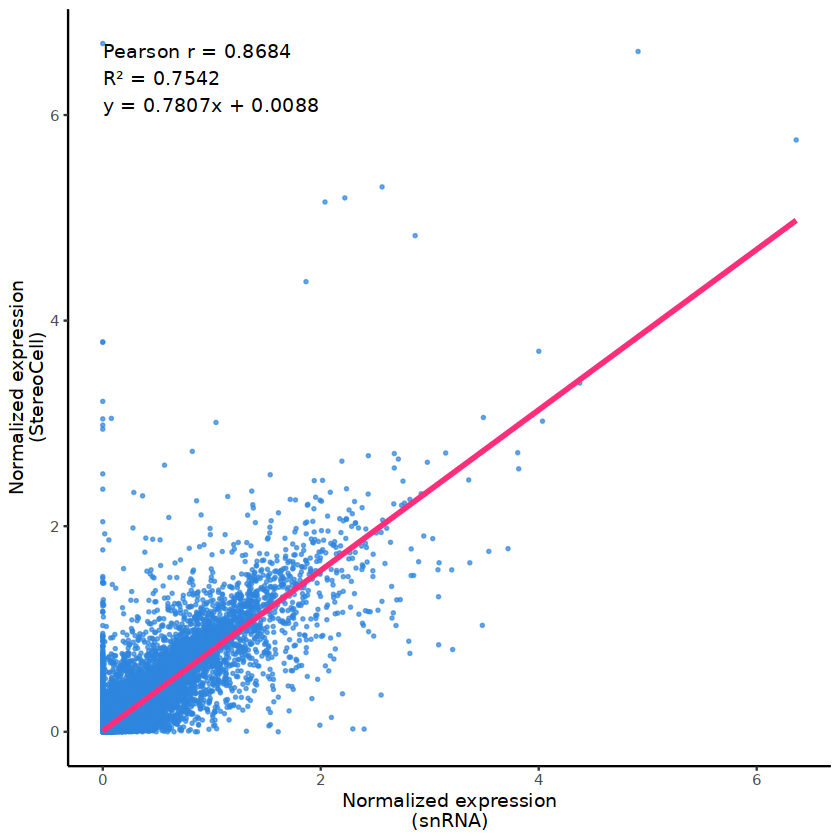

In [ ]:
avg_expr <- AverageExpression(
  obj, assays = "RNA", slot = "data",
  group.by = "source", verbose = FALSE
)$RNA

df <- data.frame(
  x = log1p(avg_expr[, "snRNA"]),
  y = log1p(avg_expr[, "StereoCell"])
)

fit <- lm(y ~ x, data = df)
r <- cor(df$x, df$y)
r2 <- summary(fit)$r.squared
cf <- coef(fit)

lab <- paste0(
  "Pearson r = ", sprintf("%.4f", r), "\n",
  "R² = ", sprintf("%.4f", r2), "\n",
  "y = ", sprintf("%.4f", cf[2]), "x ",
  ifelse(cf[1] >= 0, "+ ", "- "),
  sprintf("%.4f", abs(cf[1]))
)

p <- ggplot(df, aes(x, y)) +
  geom_point(size = 0.5, alpha = 0.7, color = "#2E86DE") +
  geom_smooth(method = "lm", se = FALSE, color = "#FF2D7A", linewidth = 1.2) +
  annotate("text", min(df$x), max(df$y), label = lab,
           hjust = 0, vjust = 1, size = 4) +
  labs(
    x = "Normalized expression\n(snRNA)",
    y = "Normalized expression\n(StereoCell)"
  ) +
  theme_classic()

pdf("Merge-Cochlea-Expression-Correlation.pdf", 4.5, 4.5)
print(p)
dev.off()

p

`geom_smooth()` using formula = 'y ~ x'


pdf 
  2

`geom_smooth()` using formula = 'y ~ x'


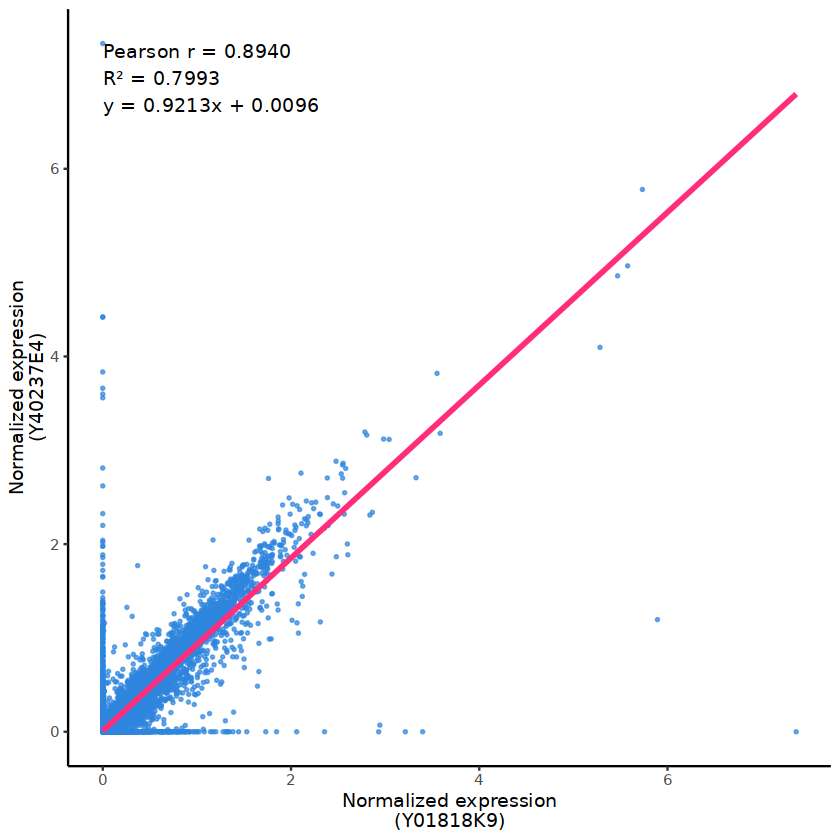

In [ ]:
avg <- AverageExpression(obj, assays="RNA", slot="data", group.by="sample", verbose=FALSE)$RNA

df <- data.frame(
  x=log1p(avg[,"Y01818K9"]),
  y=log1p(avg[,"Y40237E4"])
)

fit <- lm(y~x, df)
r <- cor(df$x, df$y)
r2 <- summary(fit)$r.squared
cf <- coef(fit)

lab <- paste0(
  "Pearson r = ",sprintf("%.4f",r),"\n",
  "R² = ",sprintf("%.4f",r2),"\n",
  "y = ",sprintf("%.4f",cf[2]),"x ",
  ifelse(cf[1]>=0,"+ ","- "),
  sprintf("%.4f",abs(cf[1]))
)

p <- ggplot(df,aes(x,y)) +
  geom_point(size=.5,alpha=.7,color="#2E86DE") +
  geom_smooth(method="lm",se=FALSE,color="#FF2D7A",linewidth=1.2) +
  annotate("text",min(df$x),max(df$y),label=lab,hjust=0,vjust=1,size=4) +
  labs(x="Normalized expression\n(Y01818K9)",
       y="Normalized expression\n(Y40237E4)") +
  theme_classic()

pdf("Merge-Cochlea-StereoCell-Correlation.pdf",4.5,4.5)
print(p)
dev.off()
p

In [ ]:
rna <- GetAssayData(obj,assay="RNA",slot="counts")

sn_cells <- colnames(obj)[which(obj$source=="snRNA")]
st_cells <- colnames(obj)[which(obj$source=="StereoCell")]

prop_sn <- Matrix::rowMeans(
  rna[,sn_cells,drop=FALSE] > 0,
  na.rm=TRUE
)

prop_st <- Matrix::rowMeans(
  rna[,st_cells,drop=FALSE] > 0,
  na.rm=TRUE
)

genes_sn <- rownames(rna)[
  !is.na(prop_sn) & prop_sn >= 0.01
]

genes_st <- rownames(rna)[
  !is.na(prop_st) & prop_st >= 0.01
]

genes_sn <- unique(genes_sn[!is.na(genes_sn) & genes_sn!=""])
genes_st <- unique(genes_st[!is.na(genes_st) & genes_st!=""])

cat("snRNA cells:",length(sn_cells),"\n")
cat("StereoCell cells:",length(st_cells),"\n")
cat("snRNA genes:",length(genes_sn),"\n")
cat("StereoCell genes:",length(genes_st),"\n")
cat("Shared genes:",length(intersect(genes_sn,genes_st)),"\n")
cat("NA in genes_sn:",sum(is.na(genes_sn)),"\n")
cat("NA in genes_st:",sum(is.na(genes_st)),"\n")

pdf("Merge-Cochlea-gene-Venn.pdf",5,5)

grid.draw(
  venn.diagram(
    list(
      snRNA=genes_sn,
      StereoCell=genes_st
    ),
    filename=NULL,
    fill=c("#95e1d3","#fce38a"),
    alpha=.6,
    cex=1.5,
    cat.cex=1.3
  )
)

dev.off()

snRNA cells: 2620 
StereoCell cells: 11306 
snRNA genes: 13043 
StereoCell genes: 14598 
Shared genes: 11831 
NA in genes_sn: 0 
NA in genes_st: 0 


pdf 
  2

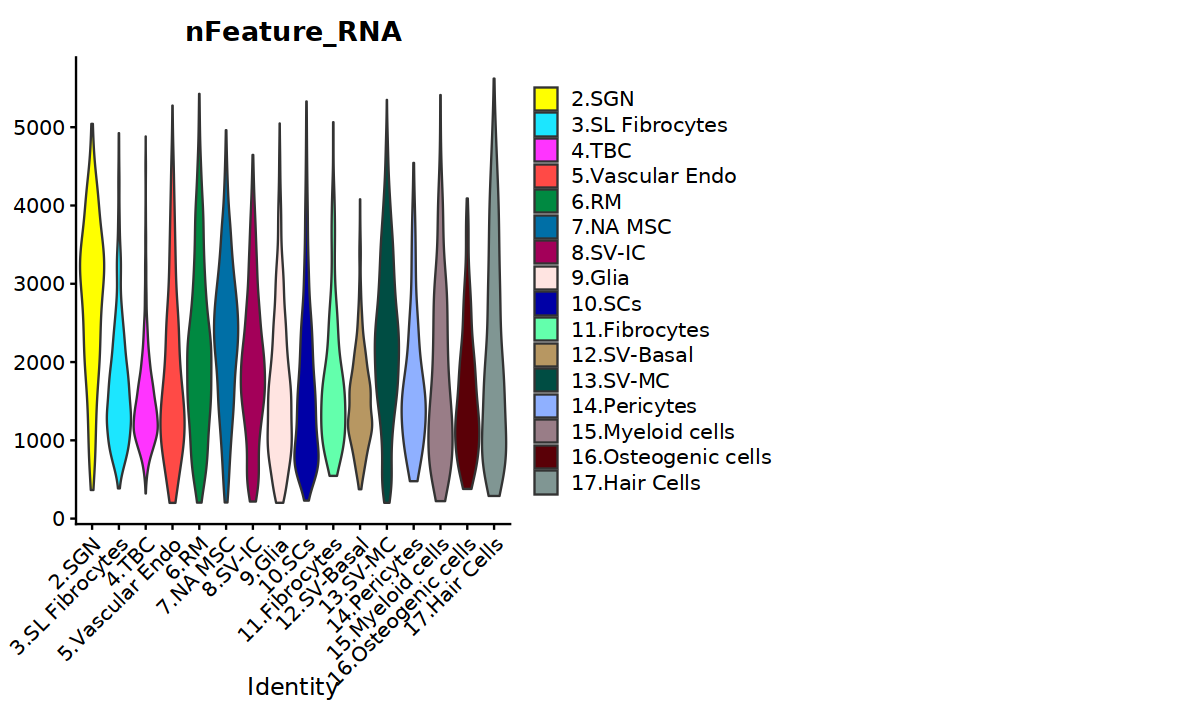

In [ ]:
p <- VlnPlot(
  obj,
  features = c("nFeature_RNA"),
  group.by = "celltype_1013",
  pt.size = 0,
  cols = colorlist, 
  ncol = 2
)
p
ggsave('Merge-Cochlea-QC-celltype-1.pdf', p, width = 12, height = 5)
